# 08 - Hourly weather, 2015-2025

**Goal:** add hourly weather for Seoul over the period of the extended pollution data (notebook 07): wind, precipitation, humidity, temperature, pressure and the boundary layer height, the depth of the air layer in which pollution mixes. The code lives in `src/seoul_air/weather.py`.

> **Observed weather is for analysis, not for forecasting.** The weather of a day is only known once the day has passed. A forecast for day *d+1* issued at the end of day *d* may use the weather of day *d* and earlier, or a weather *forecast* for *d+1*; it may never use the observed weather of *d+1*. Section 7 shows the helper that enforces this.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air import weather
from seoul_air.episodes import find_runs
from seoul_air.features import make_forecast_table
from seoul_air.report import save_key_figures
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

## 2. Sources

In [2]:
pd.set_option("display.max_colwidth", 80)
weather.WEATHER_SOURCES.set_index("source").drop(columns="url").T

source,ERA5 reanalysis via Open-Meteo,KMA ASOS 108 Seoul via Meteostat,"KMA ASOS 108 Seoul, official"
role,weather of the analysis (all variables),check of ERA5 against measurements,not used
what,"model reconstruction of past weather, 0.25-degree grid; nearest grid point t...",observations of the official Seoul surface station (WMO 47108),the same station from the KMA data portals
time,UTC instants; precipitation = total of the hour before,"UTC instants; 3-hourly before 2018, hourly from 2021",KST
key_needed,no,no,yes (KMA API Hub or data.go.kr)
licence,ERA5: Copernicus licence (attribution); Open-Meteo data: CC BY 4.0,Meteostat: CC BY-NC 4.0 (not redistributed here),KOGL


**Interpretation.** ERA5 is the weather of the analysis: it covers every hour, has all the variables, including the boundary layer height that no surface station measures, and needs no key. Its limits: it is a model reconstruction rather than a measurement, and one grid point stands for the whole city. The official KMA station data would need a personal key from the KMA portals; the same station's observations, read through Meteostat, are used only to check ERA5 and are not redistributed.

## 3. Download, units and missing data

In [3]:
era5 = weather.read_era5(weather.download_era5())
station_path = weather.download_station_observations()
print("ERA5 grid point (lat, lon):", era5.attrs["grid_point"])
print("Instants (UTC):", len(era5), "from", era5["time_utc"].min(), "to", era5["time_utc"].max())
units = pd.DataFrame([{"column": column, "ERA5 variable": variable, "unit": unit}
                      for variable, (column, unit) in weather.VARIABLES.items()])
units

ERA5 grid point (lat, lon): (37.5, 127.0)
Instants (UTC): 96456 from 2014-12-31 00:00:00 to 2025-12-31 23:00:00


,column,ERA5 variable,unit
0,temperature_c,temperature_2m,degC
1,relative_humidity_pct,relative_humidity_2m,%
2,precipitation_mm,precipitation,mm per hour
3,wind_speed_ms,wind_speed_10m,m/s
4,wind_direction_deg,wind_direction_10m,"degrees, direction the wind blows from"
5,boundary_layer_height_m,boundary_layer_height,m
6,surface_pressure_hpa,surface_pressure,hPa


In [4]:
missing = era5.drop(columns="time_utc").isna().groupby(era5["time_utc"].dt.year).sum()
print("Missing instants per year:")
print(missing.loc[:, missing.sum() > 0].to_string())
gaps = find_runs(era5.set_index("time_utc")["boundary_layer_height_m"].isna())
gaps.rename(columns={"days": "hours"})

Missing instants per year:
          boundary_layer_height_m
time_utc                         
2014                            0
2015                            0
2016                            0
2017                            0
2018                            0
2019                            0
2020                            0
2021                            0
2022                            0
2023                            0
2024                         4368
2025                            0


,start,end,hours
0,2024-01-01,2024-06-30 23:00:00,4368


**Interpretation.** ERA5 has no missing value except the boundary layer height, which is missing for 4,368 hours: every hour from 2024-01-01 to 2024-06-30 (UTC). The gap is in the Open-Meteo archive (the same request returns empty values for that half-year) and is left missing, not interpolated. Filling it would need the ERA5 files from the Copernicus Climate Data Store, which requires a free account and key.

## 4. From UTC instants to KST hours

The pollution tables label each hour by its start in KST. Hour [h, h+1) KST gets the mean of the ERA5 instants at h and h+1 (wind direction from the mean wind components) and the precipitation reported at h+1, which fell during that hour. The example shows the first two hours of 2015.

In [5]:
example = era5.head(17).tail(3)[["time_utc", "temperature_c", "precipitation_mm"]]
example.insert(1, "time_kst", example["time_utc"] + weather.KST)
print(example.to_string(index=False))
hourly = weather.to_kst_hours(era5)
hourly = hourly[(hourly["datetime"] >= "2015-01-01") & (hourly["datetime"] < "2026-01-01")].reset_index(drop=True)
print()
print(hourly.head(2)[["datetime", "temperature_c", "precipitation_mm"]].to_string(index=False))
print("\nKST hours:", len(hourly), "| hours with any missing variable:", int(hourly[weather.WEATHER_COLUMNS].isna().any(axis=1).sum()))
hourly[weather.WEATHER_COLUMNS].describe().T[["mean", "min", "50%", "max"]].round(2)

           time_utc            time_kst  temperature_c  precipitation_mm
2014-12-31 14:00:00 2014-12-31 23:00:00           -5.3               0.0
2014-12-31 15:00:00 2015-01-01 00:00:00           -5.6               0.0
2014-12-31 16:00:00 2015-01-01 01:00:00           -5.7               0.0

           datetime  temperature_c  precipitation_mm
2015-01-01 00:00:00          -5.65               0.0
2015-01-01 01:00:00          -6.40               0.0

KST hours: 96432 | hours with any missing variable: 4369


,mean,min,50%,max
temperature_c,13.29,-17.70,14.35,37.85
relative_humidity_pct,69.95,11.50,72.50,100.00
precipitation_mm,0.13,0.00,0.00,33.50
wind_speed_ms,2.46,0.00,2.16,14.09
wind_direction_deg,199.18,0.00,218.62,359.99
wind_u_ms,0.58,-10.19,0.65,10.50
wind_v_ms,0.01,-7.70,-0.00,14.00
boundary_layer_height_m,450.29,10.00,325.00,3035.00
surface_pressure_hpa,1012.42,980.85,1012.45,1035.25


**Interpretation.** The UTC instant 15:00 of 31 December 2014 is 00:00 KST on 1 January 2015, so the first KST hour of 2015 averages the instants of 15:00 and 16:00 UTC (-5.6 and -5.7 degC give -5.65). The table has 96,432 KST hours from 2015 to 2025, and 4,369 of them lack a variable: the boundary layer height gap plus the hour at its edge. Hourly precipitation is 0 mm in most hours (median 0.0) and reaches 33.5 mm; the mean boundary layer height is 450.29 m.

## 5. How close is ERA5 to the Seoul station?

ERA5 values of a grid point are compared with the observations of the Seoul surface station (ASOS 108) at the same UTC instants. The station reported every 3 hours before 2018 and every hour from 2021; precipitation is available from 2022, so daily totals are compared on KST days with all 24 hourly reports.

In [6]:
observed = weather.read_station_observations(station_path)
print("Station reports per year:", observed.groupby(observed["time_utc"].dt.year).size().to_dict())
both = era5.merge(observed, on="time_utc", suffixes=("_era5", "_station"))
rows = []
for column in ["temperature_c", "relative_humidity_pct", "wind_speed_ms"]:
    pair = both[[f"{column}_era5", f"{column}_station"]].dropna()
    difference = pair.iloc[:, 0] - pair.iloc[:, 1]
    rows.append({"variable": column, "hours": len(pair), "correlation": pair.corr().iloc[0, 1],
                 "bias_era5_minus_station": difference.mean(), "mae": difference.abs().mean()})
hourly_check = pd.DataFrame(rows).set_index("variable")
hourly_check.round(3)

Station reports per year: {2015: 2902, 2016: 2918, 2017: 2917, 2018: 5555, 2019: 5325, 2020: 6752, 2021: 8760, 2022: 8760, 2023: 8760, 2024: 8784, 2025: 7954}


,hours,correlation,bias_era5_minus_station,mae
variable,,,,
temperature_c,69386,0.993,-0.389,1.066
relative_humidity_pct,69383,0.889,7.588,9.141
wind_speed_ms,69382,0.671,0.018,0.826


In [7]:
station_hours = observed.assign(datetime=observed["time_utc"] + weather.KST - pd.Timedelta(hours=1))
station_days = (station_hours.assign(date=station_hours["datetime"].dt.normalize())
                .groupby("date")["precipitation_mm"].agg(["sum", "count"]))
station_days = station_days[station_days["count"] == 24]["sum"].rename("station")
daily_wx = weather.daily_weather(hourly)
rain = daily_wx.set_index("date")["precipitation_mm"].rename("era5").to_frame().join(station_days, how="inner")
rain_check = {
    "days": len(rain),
    "correlation": rain.corr().loc["era5", "station"],
    "mean_station_mm": rain["station"].mean(),
    "mean_era5_mm": rain["era5"].mean(),
    "wet_day_agreement": ((rain["station"] >= 1) == (rain["era5"] >= 1)).mean(),
}
pd.Series(rain_check).round(3)

days                 1247.000
correlation             0.844
mean_station_mm         5.380
mean_era5_mm            4.096
wet_day_agreement       0.918
dtype: float64

**Interpretation.** ERA5 follows the Seoul station closely for temperature (correlation 0.993, bias -0.389 degC) and fairly well for humidity (0.889, but 7.588 points more humid) and wind speed (0.671, bias 0.018 m/s, MAE 0.826 m/s): wind varies over short distances, and a 25 km grid cell smooths it. Daily precipitation correlates at 0.844 over 1,247 days, and ERA5 agrees with the station on whether a day had at least 1 mm on 91.8% of them, but it gives less rain on those days (4.096 mm against 5.380 on average). ERA5 is therefore suitable for describing the weather of a day and its variation, while absolute humidity and rain amounts carry a known bias.

## 6. Join with the pollution data

In [8]:
air_daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet")
air_weather = weather.join_daily(air_daily, daily_wx)
hourly.to_parquet(config.DATA_PROCESSED / "weather_hourly_2015_2025.parquet", index=False)
daily_wx.to_parquet(config.DATA_PROCESSED / "weather_daily_2015_2025.parquet", index=False)
air_weather.to_parquet(config.DATA_PROCESSED / "air_weather_daily_2015_2025.parquet", index=False)
daily_columns = [c for c in daily_wx.columns if c != "date"]
print("Station-days:", len(air_daily), "| after the join:", len(air_weather),
      "| with every daily weather value:", int(air_weather[daily_columns].notna().all(axis=1).sum()))
print("Days without a daily boundary layer height:", int(daily_wx["boundary_layer_height_mean_m"].isna().sum()))

air_hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly_2015_2025.parquet", columns=["datetime", "station_code", "pm25"])
joined_hourly = weather.join_hourly(air_hourly, hourly)
print("Station-hours:", len(air_hourly), "| after the hourly join:", len(joined_hourly),
      "| with temperature:", int(joined_hourly["temperature_c"].notna().sum()))
del joined_hourly

Station-days: 100450 | after the join: 100450 | with every daily weather value: 95875
Days without a daily boundary layer height: 183


Station-hours: 2410800 | after the hourly join: 2410800 | with temperature: 2410800


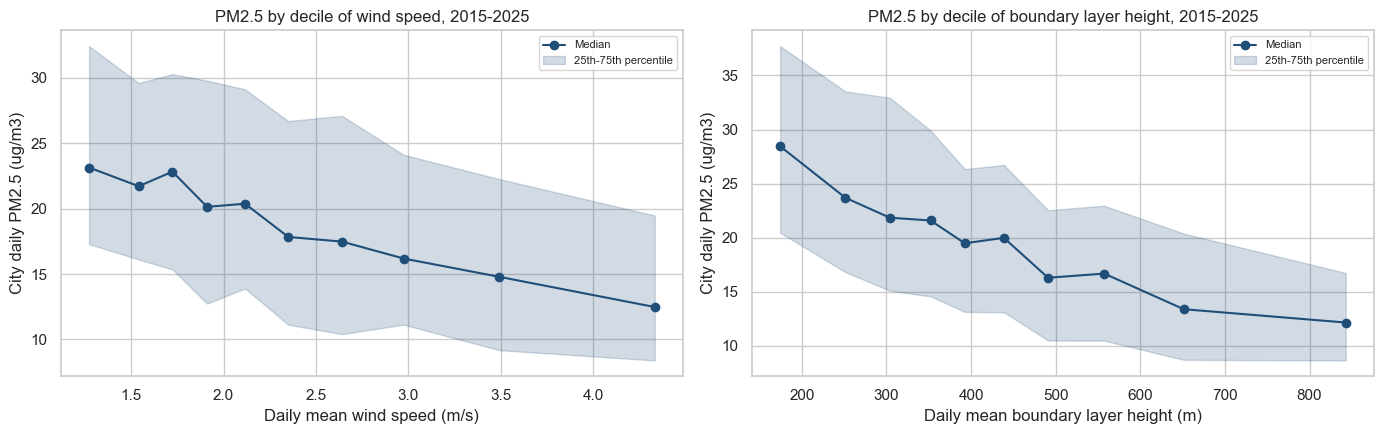

Spearman correlation with the city daily PM2.5:


,all days,Dec-Feb,Mar-May,Jun-Aug,Sep-Nov
wind_speed_mean_ms,-0.29,-0.40,-0.38,-0.42,-0.39
boundary_layer_height_mean_m,-0.39,-0.53,-0.47,-0.25,-0.49
precipitation_mm,-0.25,0.03,-0.25,-0.33,-0.21
relative_humidity_mean_pct,-0.07,0.50,0.02,-0.18,0.09
temperature_mean_c,-0.25,0.38,-0.10,0.06,-0.31


In [9]:
# A first look at the associations: city-wide daily PM2.5 against the weather of the same day
city = air_weather.groupby("date").agg(pm25=("pm25", "mean")).join(daily_wx.set_index("date"))
columns = ["wind_speed_mean_ms", "boundary_layer_height_mean_m", "precipitation_mm",
           "relative_humidity_mean_pct", "temperature_mean_c"]
season = city.index.month.map({12: "Dec-Feb", 1: "Dec-Feb", 2: "Dec-Feb", 3: "Mar-May", 4: "Mar-May", 5: "Mar-May",
                               6: "Jun-Aug", 7: "Jun-Aug", 8: "Jun-Aug", 9: "Sep-Nov", 10: "Sep-Nov", 11: "Sep-Nov"})
spearman = pd.DataFrame({name: group[columns].corrwith(group["pm25"], method="spearman")
                         for name, group in city.groupby(season)})
spearman["all days"] = city[columns].corrwith(city["pm25"], method="spearman")
spearman = spearman[["all days", "Dec-Feb", "Mar-May", "Jun-Aug", "Sep-Nov"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, column, label in [(axes[0], "wind_speed_mean_ms", "Daily mean wind speed (m/s)"),
                          (axes[1], "boundary_layer_height_mean_m", "Daily mean boundary layer height (m)")]:
    bins = pd.qcut(city[column], 10)
    summary = city.groupby(bins, observed=True)["pm25"].quantile([0.25, 0.5, 0.75]).unstack()
    centers = city.groupby(bins, observed=True)[column].median()
    ax.plot(centers, summary[0.5], marker="o", color="#1f4e79", label="Median")
    ax.fill_between(centers, summary[0.25], summary[0.75], color="#1f4e79", alpha=0.2, label="25th-75th percentile")
    ax.set_xlabel(label)
    ax.set_ylabel("City daily PM2.5 (ug/m3)")
    ax.legend(fontsize=8)
axes[0].set_title("PM2.5 by decile of wind speed, 2015-2025")
axes[1].set_title("PM2.5 by decile of boundary layer height, 2015-2025")
fig.tight_layout()
fig.savefig(config.FIGURES / "08_pm25_vs_weather.png", dpi=120)
plt.show()
print("Spearman correlation with the city daily PM2.5:")
spearman.round(2)

**Interpretation.** Every pollution row finds its weather: the daily join keeps all 100,450 station-days, and 95,875 have every daily weather value (the rest are the 183 days without a boundary layer height). Over all days, city PM2.5 is lower on windier days (Spearman -0.29), with a deeper boundary layer (-0.39) and on wetter days (-0.25); the associations with wind and the boundary layer are stronger within each season (down to -0.53 for the boundary layer in December-February). Humidity and temperature change sign with the season: in December-February, PM2.5 is higher on more humid (0.50) and warmer (0.38) days. These are associations of the same day, not causes: weather and pollution share drivers such as the season and the origin of air masses. They are the variables that a weather-adjusted analysis of the trend can use.

## 7. Weather in a forecast

`weather_known_at_issue` adds weather to a forecast table by the **issue** day: lag 0 is the weather of the day on whose evening the forecast is issued, lag 1 the day before. It refuses negative lags, which would reach into the target day. Using the observed weather of the target day would give a forecast information that it cannot have; a real forecast would need a weather forecast for that day.

In [10]:
forecast_table = make_forecast_table(air_daily[air_daily["date"].dt.year == 2024])
with_weather = weather.weather_known_at_issue(forecast_table, daily_wx[["date", "wind_speed_mean_ms"]], lags=(0, 1))
row = with_weather.dropna(subset=["target"]).iloc[0]
print("Issue day:", row["date"].date(), "| target day:", row["target_date"].date())
print("Wind of the issue day (lag 0):", round(row["wind_speed_mean_ms_lag0"], 2), "m/s")
print("Wind of the day before (lag 1):", round(row["wind_speed_mean_ms_lag1"], 2), "m/s")
print("Wind of the target day (not added):",
      round(daily_wx.set_index("date").loc[row["target_date"], "wind_speed_mean_ms"], 2), "m/s")
try:
    weather.weather_known_at_issue(forecast_table, daily_wx, lags=(-1,))
except ValueError as error:
    print("lag -1 refused:", error)

Issue day: 2024-01-01 | target day: 2024-01-02
Wind of the issue day (lag 0): 1.78 m/s
Wind of the day before (lag 1): 2.4 m/s
Wind of the target day (not added): 1.67 m/s
lag -1 refused: a negative lag would use weather from after the issue day


## 8. Key figures

In [11]:
save_key_figures("08", {
    "grid_point": list(era5.attrs["grid_point"]),
    "kst_hours": len(hourly),
    "blh_missing_hours": int(hourly["boundary_layer_height_m"].isna().sum()),
    "hourly_check": hourly_check.to_dict(orient="index"),
    "rain_check": rain_check,
    "spearman_all_days": spearman["all days"].to_dict(),
})
print((config.METRICS / "08_key_figures.json").read_text())

{
  "blh_missing_hours": 4369,
  "grid_point": [
    37.5,
    127.0
  ],
  "hourly_check": {
    "relative_humidity_pct": {
      "bias_era5_minus_station": 7.587838519522073,
      "correlation": 0.8893530915704292,
      "hours": 69383,
      "mae": 9.14055316143724
    },
    "temperature_c": {
      "bias_era5_minus_station": -0.3891577551667484,
      "correlation": 0.9926524762598589,
      "hours": 69386,
      "mae": 1.0659196379673133
    },
    "wind_speed_ms": {
      "bias_era5_minus_station": 0.017849410189642534,
      "correlation": 0.6708378099916088,
      "hours": 69382,
      "mae": 0.8255782479605663
    }
  },
  "kst_hours": 96432,
  "rain_check": {
    "correlation": 0.8438658151986952,
    "days": 1247,
    "mean_era5_mm": 4.095990376904571,
    "mean_station_mm": 5.380352846832397,
    "wet_day_agreement": 0.9182036888532478
  },
  "spearman_all_days": {
    "boundary_layer_height_mean_m": -0.39331789042396076,
    "precipitation_mm": -0.24849656381747362,
    